In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [ ]:
# Load dataset
df = pd.read_csv("Online_Retail.csv")

In [ ]:
# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
# Display dataset Information
df.info()

# Display statistical Summary
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83407 entries, 0 to 83406
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    83407 non-null  object 
 1   StockCode    83406 non-null  object 
 2   Description  83140 non-null  object 
 3   Quantity     83406 non-null  float64
 4   InvoiceDate  83406 non-null  object 
 5   UnitPrice    83406 non-null  float64
 6   CustomerID   53202 non-null  float64
 7   Country      83406 non-null  object 
dtypes: float64(3), object(5)
memory usage: 5.1+ MB


,Quantity,UnitPrice,CustomerID
count,83406.000000,83406.000000,53202.000000
mean,8.497302,5.476985,15343.549528
std,367.713672,129.421959,1766.676626
min,-74215.000000,0.000000,12346.000000
25%,1.000000,1.250000,13862.000000
50%,3.000000,2.510000,15311.000000
75%,8.000000,4.240000,16985.000000
max,74215.000000,16888.020000,18283.000000


In [ ]:
# Check for Missing Values
df.isna().sum()

,0
InvoiceNo,0
StockCode,1
Description,267
Quantity,1
InvoiceDate,1
UnitPrice,1
CustomerID,30205
Country,1


In [ ]:
# Remove rows with missing CustomerID and Description
df = df.dropna(subset=["CustomerID", "Description"])

In [ ]:
# Convert invoice dates into datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [ ]:
# Remove cancelled invoices
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
]

In [ ]:

# Remove rows with non-positive quantity or price
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

In [ ]:
# Calculate total sales amount
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

In [ ]:

# Show first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
# Summarize transactions for each customer
customer_data = df.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    TotalQuantity=("Quantity", "sum"),
    Monetary=("TotalAmount", "sum"),
    LastPurchase=("InvoiceDate", "max")
).reset_index()

# Calculate days since the customer's last purchase
latest_date = df["InvoiceDate"].max()

customer_data["Recency"] = (
    latest_date - customer_data["LastPurchase"]
).dt.days

customer_data.head()

,CustomerID,Frequency,TotalQuantity,Monetary,LastPurchase,Recency
0,12346.0,1,74215.0,77183.60,2011-01-18 10:01:00,20
1,12347.0,2,634.0,1187.18,2011-01-26 14:30:00,11
2,12348.0,2,1855.0,1120.24,2011-01-25 10:42:00,13
3,12350.0,1,197.0,334.40,2011-02-02 16:01:00,4
4,12356.0,1,1216.0,2271.62,2011-01-18 09:50:00,20


In [ ]:
# Select features used for customer segmentation
features = customer_data[
    ["Frequency", "TotalQuantity", "Monetary", "Recency"]
]

# Scale features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

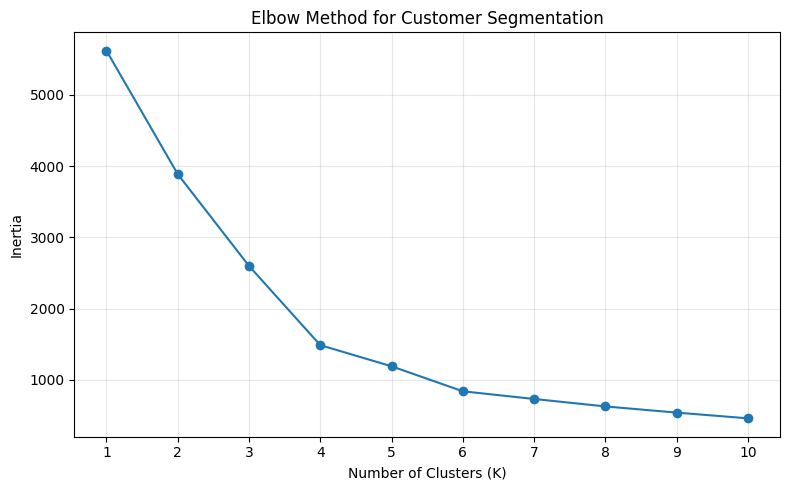

In [ ]:
# Use the Elbow Method to compare different cluster counts
inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(scaled_features)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Customer Segmentation")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Group customers into four clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_data["Segment"] = kmeans.fit_predict(scaled_features)

customer_data.head()

,CustomerID,Frequency,TotalQuantity,Monetary,LastPurchase,Recency,Segment
0,12346.0,1,74215.0,77183.60,2011-01-18 10:01:00,20,2
1,12347.0,2,634.0,1187.18,2011-01-26 14:30:00,11,3
2,12348.0,2,1855.0,1120.24,2011-01-25 10:42:00,13,3
3,12350.0,1,197.0,334.40,2011-02-02 16:01:00,4,3
4,12356.0,1,1216.0,2271.62,2011-01-18 09:50:00,20,3


In [ ]:
# Assign names to customer segments
segment_names = {
    0: "Regular Customers",
    1: "Loyal Customers",
    2: "High-Spending Customers",
    3: "At-Risk Customers"
}

customer_data["Segment_Name"] = customer_data["Segment"].map(segment_names)

customer_data.head()

,CustomerID,Frequency,TotalQuantity,Monetary,LastPurchase,Recency,Segment,Segment_Name
0,12346.0,1,74215.0,77183.60,2011-01-18 10:01:00,20,2,High-Spending Customers
1,12347.0,2,634.0,1187.18,2011-01-26 14:30:00,11,3,At-Risk Customers
2,12348.0,2,1855.0,1120.24,2011-01-25 10:42:00,13,3,At-Risk Customers
3,12350.0,1,197.0,334.40,2011-02-02 16:01:00,4,3,At-Risk Customers
4,12356.0,1,1216.0,2271.62,2011-01-18 09:50:00,20,3,At-Risk Customers


In [ ]:
#Summarize customers using the labels
segment_summary = customer_data.groupby("Segment_Name").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Orders=("Frequency", "mean"),
    Average_Quantity=("TotalQuantity", "mean"),
    Average_Spending=("Monetary", "mean"),
    Average_Recency=("Recency", "mean")
).round(2)

segment_summary

,Customer_Count,Average_Orders,Average_Quantity,Average_Spending,Average_Recency
Segment_Name,,,,,
At-Risk Customers,851,1.96,420.16,772.33,15.03
High-Spending Customers,1,1.00,74215.00,77183.60,20.00
Loyal Customers,21,13.05,7487.24,13367.79,13.48
Regular Customers,532,1.27,239.74,412.60,58.19


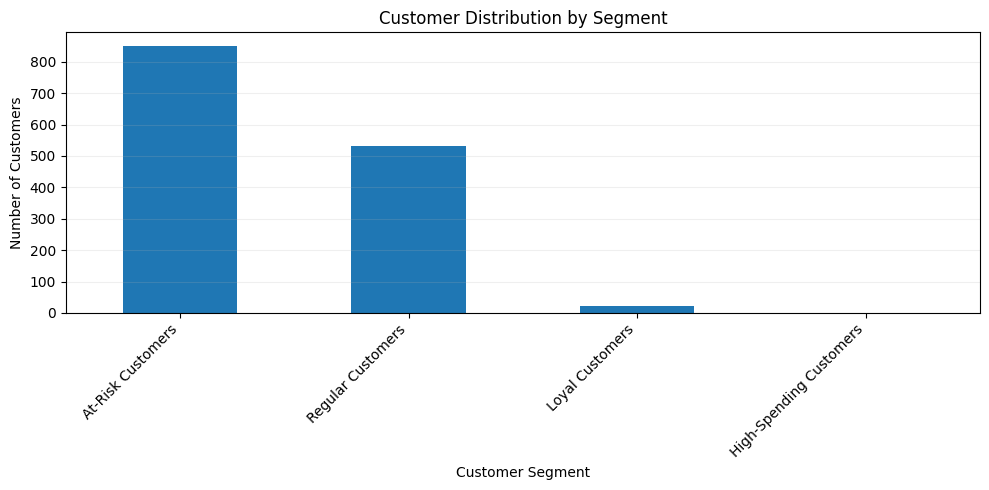

In [ ]:
# Plot the number of customers in each segment
customer_counts = customer_data["Segment_Name"].value_counts()

plt.figure(figsize=(10, 5))
customer_counts.plot(kind="bar")

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

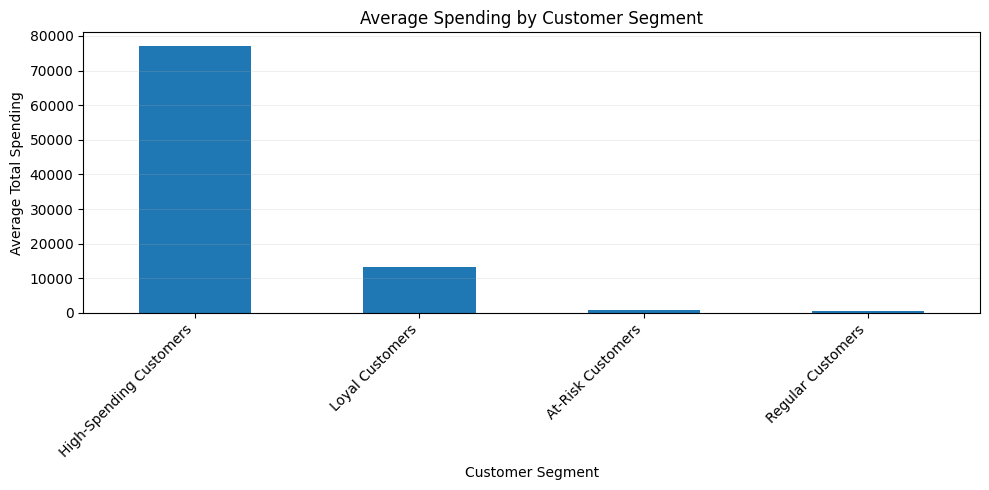

In [ ]:
# Compare average customer spending
spending = customer_data.groupby("Segment_Name")[
    "Monetary"
].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
spending.plot(kind="bar")

plt.title("Average Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Total Spending")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

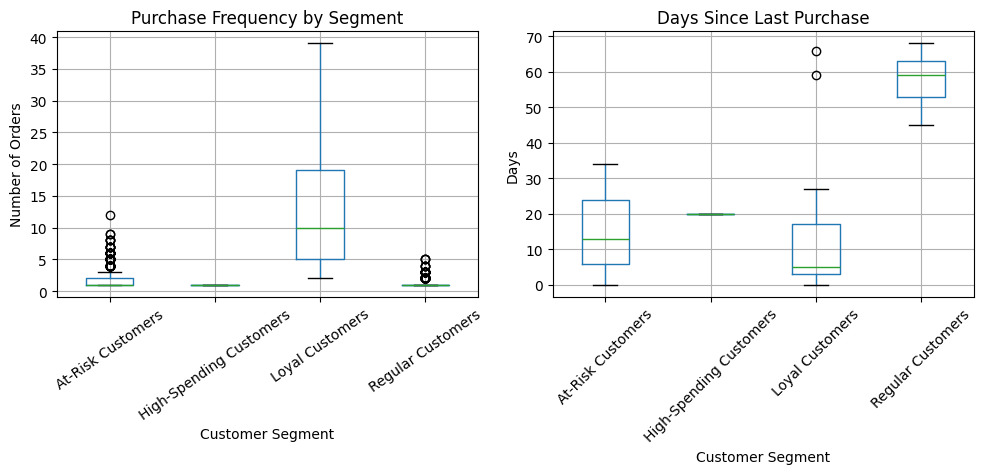

In [ ]:
# Compare purchase frequency and days since last purchase
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

customer_data.boxplot(
    column="Frequency",
    by="Segment_Name",
    ax=axes[0],
    rot=35
)
axes[0].set_title("Purchase Frequency by Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Number of Orders")

customer_data.boxplot(
    column="Recency",
    by="Segment_Name",
    ax=axes[1],
    rot=45
)
axes[1].set_title("Days Since Last Purchase")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Days")

plt.suptitle("")
plt.tight_layout()
plt.show()

In [ ]:
# Connect each transaction to its customer's segment
df_segmented = df.merge(
    customer_data[["CustomerID", "Segment_Name"]],
    on="CustomerID",
)

#Display the top five products purchased by each segmen
for name in customer_data["Segment_Name"].unique():

    top_products = (
        df_segmented[df_segmented["Segment_Name"] == name]
        .groupby("Description")["Quantity"]
        .sum()
        .sort_values(ascending=False)
        .head()
    )

    print("\nTop 5 products for:", name)
    display(top_products.to_frame("Total Quantity Sold"))


Top 5 products for: High-Spending Customers


,Total Quantity Sold
Description,
MEDIUM CERAMIC TOP STORAGE JAR,74215.0



Top 5 products for: At-Risk Customers


,Total Quantity Sold
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,5665.0
WHITE HANGING HEART T-LIGHT HOLDER,4236.0
PACK OF 12 LONDON TISSUES,3721.0
JUMBO BAG RED RETROSPOT,3258.0
ASSORTED COLOUR BIRD ORNAMENT,3231.0



Top 5 products for: Regular Customers


,Total Quantity Sold
Description,
WORLD WAR 2 GLIDERS ASSTD DESIGNS,3699.0
MINI PAINT SET VINTAGE,2088.0
RED HARMONICA IN BOX,1852.0
ASSORTED COLOUR T-LIGHT HOLDER,1848.0
ASSORTED LAQUERED INCENSE HOLDERS,1728.0



Top 5 products for: Loyal Customers


,Total Quantity Sold
Description,
WHITE HANGING HEART T-LIGHT HOLDER,4404.0
FAIRY CAKE FLANNEL ASSORTED COLOUR,3114.0
PACK OF 72 RETROSPOT CAKE CASES,2985.0
BROCADE RING PURSE,2883.0
GROW A FLYTRAP OR SUNFLOWER IN TIN,2400.0


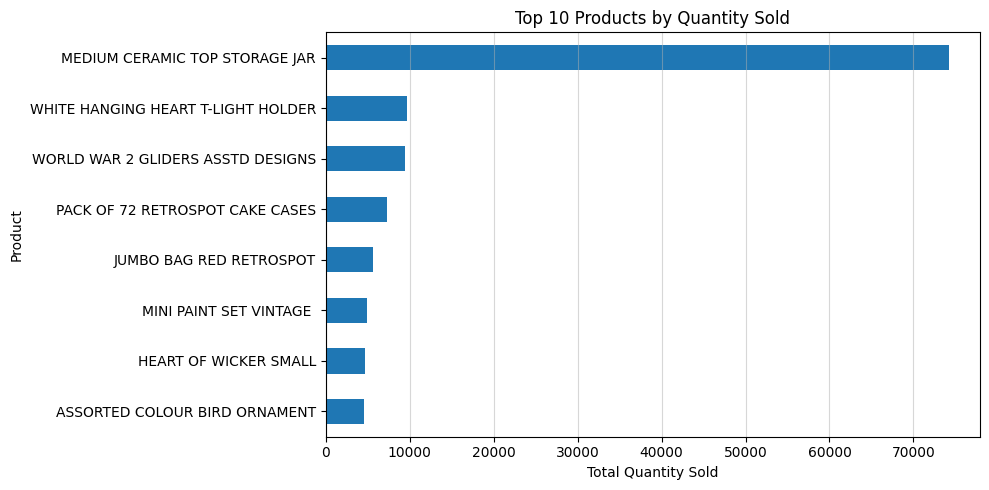

In [ ]:
# Find the ten products with the highest historical sales quantity
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .nlargest(8)
    .sort_values()
)

plt.figure(figsize=(10, 5))
top_products.plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.grid(axis="x", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Summarize historical product demand
product_summary = df.groupby("Description").agg(
    Total_Quantity_Sold=("Quantity", "sum"),
    Number_of_Orders=("InvoiceNo", "nunique"),
    Number_of_Customers=("CustomerID", "nunique"),
    Total_Revenue=("TotalAmount", "sum")
).reset_index()

# Set thresholds using the 25th and 75th percentiles
high_limit = product_summary["Total_Quantity_Sold"].quantile(0.75)
low_limit = product_summary["Total_Quantity_Sold"].quantile(0.25)

def inventory_action(quantity):
    if quantity >= high_limit:
        return "Prioritize stock monitoring"
    elif quantity <= low_limit:
        return "Review before replenishing"
    else:
        return "Maintain regular replenishment"

product_summary["Inventory_Recommendation"] = (
    product_summary["Total_Quantity_Sold"].apply(inventory_action)
)

# Show the 15 highest-quantity products
product_summary = product_summary.sort_values(
    "Total_Quantity_Sold", ascending=False
)

display(
    product_summary[
        ["Description", "Total_Quantity_Sold",
         "Number_of_Orders", "Number_of_Customers",
         "Total_Revenue", "Inventory_Recommendation"]
    ].head()
)


,Description,Total_Quantity_Sold,Number_of_Orders,Number_of_Customers,Total_Revenue,Inventory_Recommendation
1410,MEDIUM CERAMIC TOP STORAGE JAR,74215.0,1,1,77183.60,Prioritize stock monitoring
2562,WHITE HANGING HEART T-LIGHT HOLDER,9665.0,396,288,26149.85,Prioritize stock monitoring
2624,WORLD WAR 2 GLIDERS ASSTD DESIGNS,9412.0,51,44,2136.20,Prioritize stock monitoring
1609,PACK OF 72 RETROSPOT CAKE CASES,7300.0,152,133,3371.80,Prioritize stock monitoring
1264,JUMBO BAG RED RETROSPOT,5585.0,191,154,9763.95,Prioritize stock monitoring


In [ ]:
# Create a summary for each customer segment using correct column names
segment_summary = customer_data.groupby("Segment_Name").agg(
    Customers=("Segment_Name", "count"),
    PurchaseFrequency=("Frequency", "mean"),
    TotalSpend=("Monetary", "mean"),
    TotalQuantity=("TotalQuantity", "mean")
)

# Suggest the strategy matching the actual segment names in the dataset
strategy = {
    "High-Spending Customers":
        "Monitor preferred products and plan capacity for large orders.",
    "At-Risk Customers":
        "Review recent demand before replenishing; consider customer re-engagement.",
    "Loyal Customers":
        "Monitor availability of frequently purchased products and plan reliable fulfillment.",
    "Regular Customers":
        "Use standard replenishment and efficient order processing."
}

segment_summary["Supply_Chain_Strategy"] = (
    segment_summary.index.to_series().map(strategy)
)

segment_summary

,Customers,PurchaseFrequency,TotalSpend,TotalQuantity,Supply_Chain_Strategy
Segment_Name,,,,,
At-Risk Customers,851,1.956522,772.332985,420.158637,Review recent demand before replenishing; cons...
High-Spending Customers,1,1.000000,77183.600000,74215.000000,Monitor preferred products and plan capacity f...
Loyal Customers,21,13.047619,13367.785238,7487.238095,Monitor availability of frequently purchased p...
Regular Customers,532,1.266917,412.597105,239.740602,Use standard replenishment and efficient order...


In [ ]:
customer_data.to_csv("Customer_Segments.csv", index=False)
segment_summary.to_csv("Segment_Summary.csv")
product_summary.to_csv("Inventory_Planning_Recommendations.csv", index=False)

In [ ]:
from google.colab import files

files.download("Customer_Segments.csv")
files.download("Segment_Summary.csv")
files.download("Inventory_Planning_Recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>